# Lab 4 · Course Navigator
## Notebook 4 — Adapting a pretrained Transformer

Notebook 3 built and trained an encoder from random initialization. Modules 7–8 explain how pretraining changes the starting point and how to adapt an existing model. Here the architecture is still a Transformer, but its parameters already contain information learned before our course task.

**Key question:** What changes when useful language representations already exist?

### Learning objectives
- Read a model card and pin an exact pretrained checkpoint and tokenizer.
- Compare frozen features with full fine-tuning using explicit PyTorch loops.
- Explain learning-rate choice, catastrophic forgetting and low-rank adaptation.
- Evaluate the reference models honestly and select a confidence policy on validation only.

### Classroom route and independent study

Plan about **55 minutes** for the guided route. Read the explanations, predict the output, then run each cell in order. Exercises and worked answers support a slower independent review. Saved results come from real CPU runs; seeds reduce variation but cannot guarantee identical numbers across machines.

### Setup

Use Python 3.12 in a dedicated environment. Download the **complete project ZIP** from the repository, extract it, install `requirements.txt`, and select that environment as your Jupyter kernel. In Colab, the first cell clones the project when needed. If imports fail, run `%pip install -r /content/course-navigator/requirements.txt` after that clone, restart the runtime and rerun from the top. Training needs no API key or paid service. The bundled base checkpoint permits offline model loading after dependencies are installed.

The default route loads supplied checkpoints. Set `RUN_TRAINING = True` to reproduce the full run into a separate classroom folder; the reference results remain unchanged. A notebook download alone does not contain its dataset and checkpoints.

In [1]:
from __future__ import annotations
from pathlib import Path
import sys, json, math, random, copy, time, re
from collections import Counter
from dataclasses import dataclass

# In Colab, clone the complete project once. Locally, open this notebook from
# the extracted project folder. A lone downloaded .ipynb has no model/data files.
ROOT = Path.cwd()
if not (ROOT / "coursenav").exists():
    if "google.colab" in sys.modules:
        import subprocess
        target = Path("/content/course-navigator")
        if not target.exists():
            subprocess.run(["git", "clone", "https://github.com/solomonpromise/course-navigator.git", str(target)], check=True)
        ROOT = target
    else:
        raise FileNotFoundError("Open this notebook inside the complete Course Navigator project folder; see README.md.")
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
from sklearn.feature_extraction.text import TfidfVectorizer
import warnings
# Optional progress widgets do not affect training.
warnings.filterwarnings("ignore", message="IProgress not found.*")
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
from IPython.display import display, Markdown
from coursenav.data import LABELS, MAX_LENGTH, words, encode, load_records, fit_vocabulary, TextDataset
from coursenav.training import (TrainConfig, seed_everything, fit, logits_for, summarize,
    dataset_for, load_reference, pretrained_tokenizer, pretrained_dataset, make_model)
seed_everything(42)
train, validation, test = (load_records(split) for split in ["train", "validation", "test"])
vocabulary = json.loads((ROOT / "artifacts/vocabulary.json").read_text())
results = json.loads((ROOT / "artifacts/results.json").read_text())["models"]
RUN_TRAINING = False  # True runs training; False loads the supplied measured checkpoint.
print("PyTorch:", torch.__version__, "| Device: CPU | Maximum tokens:", MAX_LENGTH)
print("Passages:", len(train), "train /", len(validation), "validation /", len(test), "test")

PyTorch: 2.14.1 | Device: CPU | Maximum tokens: 96
Passages: 1201 train / 286 validation / 265 test


## 1. Choose a model for the constraints

We use Google’s **BERT-Tiny**, `google/bert_uncased_L-2_H-128_A-2`: two layers, hidden width 128, two attention heads and an uncased WordPiece vocabulary. The model card identifies an Apache-2.0 license and describes its compact pretrained design. A small encoder keeps this class practical on a CPU and permits an approximately 18 MB browser model.

A **checkpoint** is a saved parameter state plus configuration. A model identifier can change over time, so we also pin its revision. A **model card** describes intended uses, training background, evaluation and limitations. Permission to use a checkpoint does not establish that it is suitable for our task.

BERT’s original pretraining objectives differ from our six-topic classification objective. Pretraining does not magically teach it these labels. We attach and train a new topic head. Our comparison also changes parameter count, tokenizer and prior data, so it is not a pure architecture experiment.

Sources: [Google model card](https://huggingface.co/google/bert_uncased_L-2_H-128_A-2), [BERT documentation](https://huggingface.co/docs/transformers/model_doc/bert).

In [2]:
from coursenav.training import MODEL_ID, MODEL_REVISION
print("Model:", MODEL_ID)
print("Pinned revision:", MODEL_REVISION)
print(json.loads((ROOT / "artifacts/pretrained-source/config.json").read_text()))

Model: google/bert_uncased_L-2_H-128_A-2
Pinned revision: 30b0a37ccaaa32f332884b96992754e246e48c5f
{'attention_probs_dropout_prob': 0.1, 'hidden_act': 'gelu', 'hidden_dropout_prob': 0.1, 'hidden_size': 128, 'initializer_range': 0.02, 'intermediate_size': 512, 'layer_norm_eps': 1e-12, 'max_position_embeddings': 512, 'model_type': 'bert', 'num_attention_heads': 2, 'num_hidden_layers': 2, 'pad_token_id': 0, 'type_vocab_size': 2, 'vocab_size': 30522}


## 2. Keep the tokenizer and model together

**WordPiece** can split an unfamiliar word into known subword pieces. For example, a rare technical term may become a root and several `##` continuations. Its vocabulary is fixed by the pretrained checkpoint. Replacing it with our scratch vocabulary would send the wrong embedding rows into the model.

`[CLS]` and `[SEP]` mark sequence boundaries. `[PAD]` fills unused positions. `attention_mask=1` marks real/special tokens, and zero marks padding. `token_type_ids` distinguish sentence segments in BERT; our single-input examples use zero throughout.

Our 96-position contract leaves at most **94 content WordPieces**, plus two boundary tokens. This is not the same as 94 words. Tokenization can truncate important late context, so the app displays a truncation notice.

The constructor below uses the explicit vocabulary API tested in our pinned Transformers version. Its assertions catch a silent five-special-token fallback: an API mismatch must fail before we accept any training result.

In [3]:
def pretrained_tokenizer():
    """Use the exact bundled WordPiece vocabulary, avoiding network at inference."""
    from transformers import BertTokenizer
    vocabulary = {token: index for index, token in enumerate(
        (ROOT / "artifacts/pretrained-source/vocab.txt").read_text().splitlines())}
    tokenizer = BertTokenizer(vocab=vocabulary, do_lower_case=True)
    # Fail loudly if an API change silently created a five-special-token vocabulary.
    if tokenizer.vocab_size != 30522 or tokenizer.cls_token_id != 101:
        raise ValueError("Tokenizer does not match the pretrained BERT vocabulary")
    return tokenizer

def pretrained_dataset(rows, tokenizer=None):
    """Encode with BERT's own tokenizer; attention masks distinguish PAD from text."""
    tokenizer = tokenizer or pretrained_tokenizer()
    batch = tokenizer([row["text"] for row in rows], max_length=MAX_LENGTH,
                      padding="max_length", truncation=True, return_tensors="pt")
    return TensorDataset(batch["input_ids"], batch["attention_mask"], batch["token_type_ids"],
                         torch.tensor([row["label"] for row in rows], dtype=torch.long))

In [4]:
tokenizer = pretrained_tokenizer()
sample = "Fine-tuning a pretrained encoder changes its representations."
encoded = tokenizer(sample, padding="max_length", truncation=True, max_length=MAX_LENGTH, return_tensors="pt")
print("Pieces:", tokenizer.tokenize(sample))
print("IDs:", encoded["input_ids"][0,:16].tolist())
print("Real/special tokens:", int(encoded["attention_mask"].sum()))
assert tokenizer.vocab_size == 30522 and tokenizer.cls_token_id == 101

Pieces: ['fine', '-', 'tuning', 'a', 'pre', '##train', '##ed', 'en', '##code', '##r', 'changes', 'its', 'representations', '.']
IDs: [101, 2986, 1011, 17372, 1037, 3653, 23654, 2098, 4372, 16044, 2099, 3431, 2049, 15066, 1012, 102]
Real/special tokens: 16


## 3. Add a task head to contextual representations

The encoder returns `(B,T,128)` contextual states. Unlike the static embedding lookup from Notebook 1, a token’s final state depends on allowed surrounding tokens. Masked mean pooling turns the sequence into one 128-component vector. A new linear head maps it to six logits.

The original masked-language-model head is not our classifier and is not reused. Loading the encoder may report unused pretraining-head keys; that is expected for this deliberate architecture change. A checkpoint mismatch within our own six-topic model would be a real error.

In [5]:
class PretrainedClassifier(nn.Module):
    """Reuse a pretrained BERT encoder and learn a task-specific topic head.

    The base checkpoint supplies representations, not our six topic labels.
    Both frozen-feature and full fine-tuning experiments share this interface.
    """
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.dropout = nn.Dropout(0.1)
        self.head = nn.Linear(encoder.config.hidden_size, len(LABELS))

    def forward(self, input_ids, attention_mask, token_type_ids):
        states = self.encoder(input_ids=input_ids, attention_mask=attention_mask,
                              token_type_ids=token_type_ids).last_hidden_state
        mask = attention_mask.unsqueeze(-1).to(states.dtype)
        pooled = (states * mask).sum(1) / mask.sum(1).clamp_min(1)
        return self.head(self.dropout(pooled))

## 4. Frozen features: learn the head first

Freezing sets encoder parameters’ `requires_grad=False`. Backpropagation still trains the head. We also keep the encoder in evaluation mode during head training so dropout does not randomly change its frozen features.

This is a useful baseline: how far can existing representations take us with minimal adaptation? Its best reference validation macro-F1 is about 0.508. Frozen inference is not free—the encoder still performs its forward computations—but fewer parameters require gradients and optimizer state.

In [6]:
frozen = make_model("frozen")
display(pd.DataFrame([
    {"component": "encoder", "trainable": sum(p.numel() for p in frozen.encoder.parameters() if p.requires_grad)},
    {"component": "head", "trainable": sum(p.numel() for p in frozen.head.parameters() if p.requires_grad)},
]))
if RUN_TRAINING:
    seed_everything()
    frozen, history, seconds = fit(frozen, pretrained_dataset(train), pretrained_dataset(validation),
        TrainConfig(epochs=16, learning_rate=.008), frozen=True)
    output = ROOT / "artifacts/classroom"; output.mkdir(exist_ok=True)
    torch.save(frozen.state_dict(), output / "frozen.pt")

W1024 10:04:26.731000 54925 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


W1024 10:04:26.817000 54925 site-packages/torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1024 10:04:26.838000 54925 site-packages/torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


,component,trainable
0,encoder,0
1,head,774


## 5. Full fine-tuning: update the encoder too

**Fine-tuning** starts from pretrained weights and updates them on task data. This lets contextual representations adapt to our vocabulary and distinctions. It can also damage useful prior behavior—**catastrophic forgetting**—or overfit a small dataset.

Our predeclared reference configuration uses AdamW, learning rate 0.0002, weight decay 0.01, batch size 32, up to 12 epochs, gradient clipping and validation checkpoint selection. This rate is an experimental choice for this compact model, not a universal BERT recommendation. A larger model or different task needs its own validation protocol.

No test score selected the checkpoint or these settings. We never claim that the model acquired general teaching ability: it learned a narrow topic-routing task.

In [7]:
seed_everything()
adapted = make_model("finetuned")
print("Trainable parameters:", sum(p.numel() for p in adapted.parameters() if p.requires_grad))
if RUN_TRAINING:
    adapted, history, seconds = fit(adapted, pretrained_dataset(train), pretrained_dataset(validation),
        TrainConfig(epochs=12, learning_rate=.0002))
    output = ROOT / "artifacts/classroom"; output.mkdir(exist_ok=True)
    torch.save(adapted.state_dict(), output / "finetuned.pt")
else:
    adapted.load_state_dict(torch.load(ROOT / "artifacts/finetuned.pt", map_location="cpu", weights_only=True))
adapted.eval()
record = next(row for row in results if row["name"] == "finetuned")
display(pd.DataFrame(record["history"]))

Trainable parameters: 4370182


,epoch,train_loss,validation_macro_f1,validation_loss
0,1,1.692714,0.364516,1.484263
1,2,1.128339,0.621597,1.068846
2,3,0.708801,0.663299,0.892627
3,4,0.449864,0.696685,0.866724
4,5,0.265475,0.707378,0.891758
5,6,0.141548,0.703871,0.978692
6,7,0.071765,0.703945,1.091164
7,8,0.031272,0.716393,1.173843
8,9,0.017052,0.720790,1.199428
9,10,0.007747,0.715545,1.334967


## 6. Where LoRA fits

**Parameter-efficient fine-tuning** updates a restricted set of parameters. LoRA freezes a weight W and learns a low-rank update:

$$W_{adapted}=W+\frac{\alpha}{r}BA.$$

For a matrix with output width m and input width n, a full update has mn parameters. Rank-r factors have r(m+n). A small rank constrains the update’s capacity. This can save trainable memory and optimizer state, though it does not remove the base model’s inference cost.

We demonstrate the mechanism below. **This is not a trained LoRA experiment**, and it contributes no score to the results table. Full fine-tuning is feasible for our small checkpoint; running an additional LoRA study belongs to further learning. QLoRA additionally uses a quantized base model and introduces numerical/hardware trade-offs beyond this CPU classroom route.

In [8]:
# A shape-and-initialization demonstration, not a reported training run.
in_features, out_features, rank, alpha = 128, 128, 4, 8
base = nn.Linear(in_features, out_features, bias=False)
for parameter in base.parameters():
    parameter.requires_grad = False
A = nn.Parameter(torch.randn(rank, in_features) * .01)
B = nn.Parameter(torch.zeros(out_features, rank))
x = torch.randn(2, in_features)
original = base(x)
with_adapter = original + (alpha/rank) * (x @ A.T @ B.T)
assert torch.equal(original, with_adapter)  # zero B makes the initial update zero
print("Full matrix parameters:", in_features*out_features)
print("Adapter parameters:", A.numel()+B.numel())

Full matrix parameters: 16384
Adapter parameters: 1024


## 7. Read every model’s final evidence

The fine-tuned model reaches approximately **0.711 passage test macro-F1** and **24/36 authored questions correct**. The TF-IDF baseline reaches approximately **0.773** and **24/36**, respectively. The fine-tuned encoder wins among our neural experiments; the simpler baseline wins the passage comparison.

**Deployment decision for this lab:** we deploy fine-tuned BERT to demonstrate the complete pretrained-model adaptation and browser export workflow requested for class. We disclose its limits and keep the baseline visible. A production routing decision based only on this evidence would favor the baseline’s measured passage result, then evaluate latency, confidence, real question performance and maintenance. We do not present this educational choice as empirical superiority.

One seed and a small authored question set do not support strong statistical rankings. Classes overlap: a question about fine-tuning can also mention pretrained applications. Some labels are legitimately ambiguous; inspect mistakes rather than hiding them in a single average.

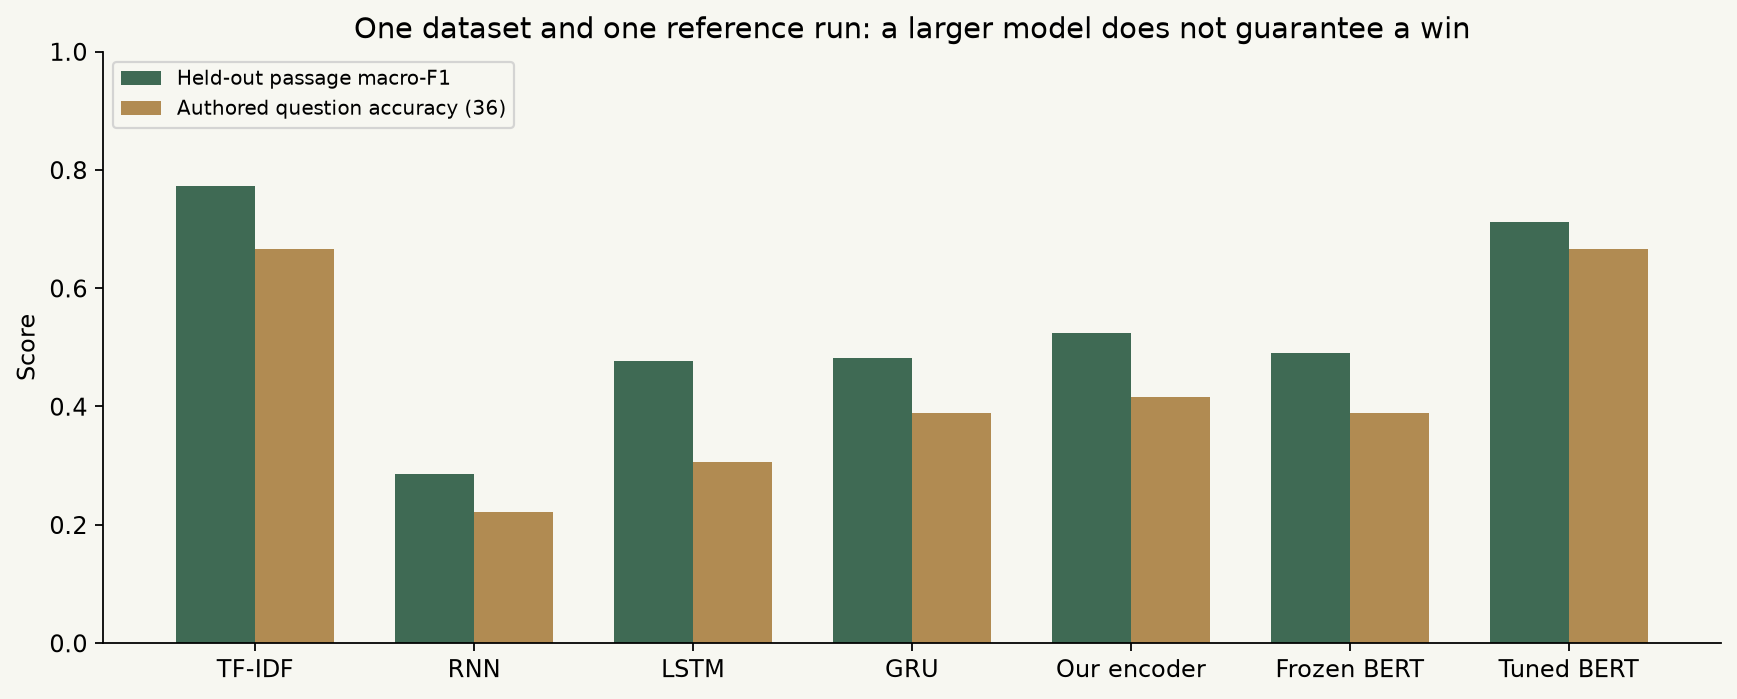

*Different metrics answer different questions. Neither bar measures actual learner satisfaction.*

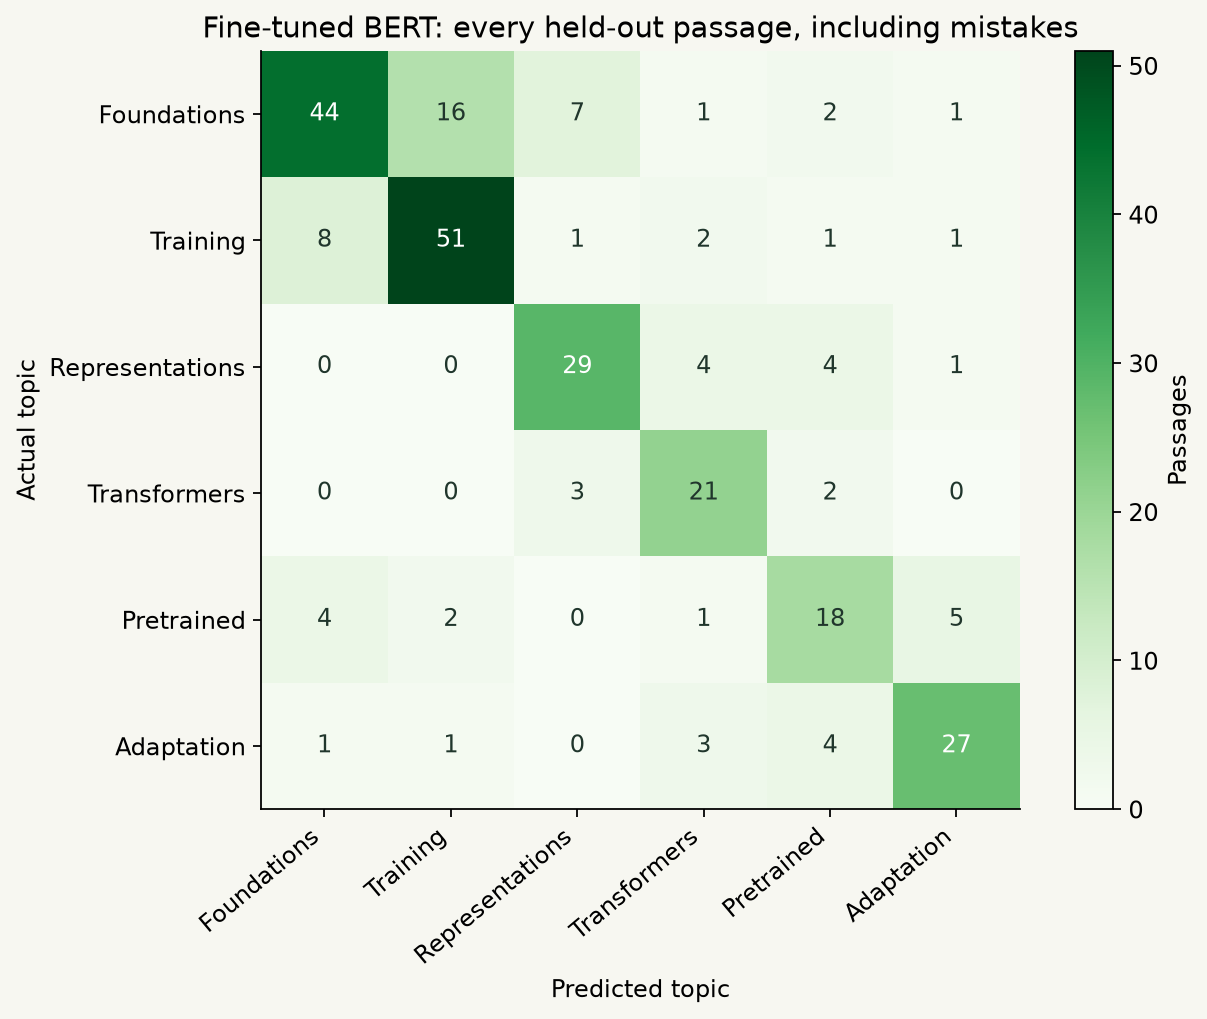

*Rows are true topics; columns are predicted topics. Off-diagonal cells are the mistakes we must investigate.*

In [9]:
summary = [{"model": row["name"], "passage macro-F1": row["test"]["macro_f1"],
            "question accuracy": row["questions"]["accuracy"], "training seconds": row["train_seconds"]} for row in results]
display(pd.DataFrame(summary).set_index("model"))

,passage macro-F1,question accuracy,training seconds
model,,,
tfidf,0.773005,0.666667,0.192537
rnn,0.285193,0.222222,6.021509
lstm,0.477304,0.305556,18.675873
gru,0.481726,0.388889,15.732495
transformer,0.523415,0.416667,21.979692
frozen,0.491102,0.388889,3.704457
finetuned,0.711192,0.666667,16.504211


## 8. Confidence is a separate engineering problem

Softmax scores often become overconfident after fitting. **Temperature scaling** divides logits by a positive scalar before softmax. It changes score sharpness without changing the winning class. The scalar is fitted on validation labels only.

The saved temperature is about 2.364. A validation-selected threshold near 0.625 marks tentative predictions; in validation it retains about 74.5% of examples with roughly 81.2% accuracy among retained examples. These are validation measurements used to choose the policy, so they are not unbiased deployment guarantees.

The app also checks whether lexical retrieval finds meaningful overlap. This is a heuristic for weak matches, not a validated out-of-domain detector. Confident unrelated questions can still fool the model. We expose uncertainty and source excerpts rather than inventing an answer.

In [10]:
policy = json.loads((ROOT / "artifacts/policy.json").read_text())
sample = tokenizer("How do I choose a learning rate?", padding="max_length", truncation=True,
                   max_length=MAX_LENGTH, return_tensors="pt")
with torch.inference_mode():
    logits = adapted(sample["input_ids"], sample["attention_mask"], sample["token_type_ids"])
raw = logits.softmax(-1)[0]
scaled = (logits/policy["temperature"]).softmax(-1)[0]
assert int(raw.argmax()) == int(scaled.argmax())
display(pd.DataFrame({"topic": LABELS, "raw": raw.numpy(), "temperature-scaled": scaled.numpy()}))

,topic,raw,temperature-scaled
0,Foundations & PyTorch,0.974998,0.727386
1,Training & evaluation,0.000701,0.034035
2,Representations & sequences,0.000272,0.022792
3,Transformers & attention,0.022195,0.146831
4,Pretrained applications,0.000208,0.020348
5,Model adaptation,0.001627,0.048608


## 9. Self-check and further learning

1. Why does a pretrained encoder still need task labels?
2. What is the difference between freezing parameters and disabling dropout?
3. Can a different tokenizer be used if its vocabulary is the same size?
4. Why should a validation-derived confidence claim be tested on new inputs?

<details><summary>Worked answers</summary>

1. Its original objective did not define our six course categories. The supervised task must teach that mapping.
2. Freezing disables parameter-gradient updates. Evaluation mode changes dropout and other train/eval behavior. A frozen encoder can still behave randomly if dropout remains active.
3. No. Token-to-ID assignments and preprocessing must match the trained embedding rows, not just their count.
4. Validation was used to choose the policy. New representative inputs test whether its apparent reliability carries over to deployment.

</details>

**Further learning:** compare LoRA with full fine-tuning under a new predeclared protocol; evaluate consented real questions; measure seed sensitivity and confidence calibration on a fresh holdout. Preserve today’s results as the reference record.

**Next:** [Notebook 5 — From trained model to deployed app](05_deployment.ipynb).